<a href="https://colab.research.google.com/github/CharalapML/ColabCode/blob/TestingBranch/3D_Earthquake_clustering1_USGSdatafromSEAsia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

#%matplotlib notebook

# from mpl_toolkits import mplot3d
# from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d import axes3d


**The followinbg data was downloaded from the USGS survey data it covers an area across SE Asia from about 2016 to 2026 and is for Earthquake greater than magnitude 4 **

In [2]:
from pathlib import Path

# Use the CSV bundled with the repo; fall back to the GitHub copy when the notebook is opened on its own (e.g. in Colab)
DATA_PATH = Path('data/EarthQuakeData_SE_Asia.csv')
DATA_URL = 'https://raw.githubusercontent.com/CharalapML/ColabCode/TestingBranch/data/EarthQuakeData_SE_Asia.csv'
df = pd.read_csv(DATA_PATH if DATA_PATH.exists() else DATA_URL)


In [3]:
df.head(5)

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-10-13T18:45:03.231Z,-5.4832,152.1364,20.842,6.0,mww,83.0,34,1.284,0.70,...,2026-10-22T15:37:40.678Z,"126 km S of Kokopo, Papua New Guinea",earthquake,5.94,4.617,0.043,52.0,reviewed,us,us
1,2026-10-08T08:07:59.721Z,5.6177,125.1838,57.803,5.5,mww,82.0,58,1.495,1.04,...,2026-10-18T06:07:28.300Z,"13 km SW of Burias, Philippines",earthquake,9.03,5.696,0.068,21.0,reviewed,us,us
2,2026-10-03T22:55:55.358Z,-9.5672,118.9078,45.951,5.9,mww,82.0,63,4.600,1.29,...,2026-10-05T18:25:35.012Z,"39 km WSW of Tambolaka, Indonesia",earthquake,9.53,6.808,0.062,25.0,reviewed,us,us
3,2026-09-26T14:08:18.875Z,-4.6288,152.8611,69.510,5.6,mww,180.0,23,0.820,0.69,...,2026-09-29T14:45:36.205Z,"72 km ESE of Kokopo, Papua New Guinea",earthquake,20.25,7.054,0.051,37.0,reviewed,us,us
4,2026-09-20T09:17:36.531Z,-5.8986,146.1073,113.000,6.4,mww,100.0,22,3.636,0.67,...,2026-10-12T16:49:37.977Z,"50 km NNE of Kainantu, Papua New Guinea",earthquake,7.35,1.936,0.039,62.0,reviewed,us,us


In [4]:
print (df[df.mag >= 4].count() )

time               689
latitude           689
longitude          689
depth              689
mag                689
magType            689
nst                303
gap                689
dmin               689
rms                689
net                689
id                 689
updated            689
place              689
type               689
horizontalError    689
depthError         689
magError           668
magNst             668
status             689
locationSource     689
magSource          689
dtype: int64


We'll use the 'quakes' dataset, what is it?  Read the documentation to find out:

In [5]:
# data('quakes', show_doc=True)
# df = data('quakes')
#print(df)
type(df)
display (df)

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-10-13T18:45:03.231Z,-5.4832,152.1364,20.842,6.0,mww,83.0,34,1.284,0.70,...,2026-10-22T15:37:40.678Z,"126 km S of Kokopo, Papua New Guinea",earthquake,5.94,4.617,0.043,52.0,reviewed,us,us
1,2026-10-08T08:07:59.721Z,5.6177,125.1838,57.803,5.5,mww,82.0,58,1.495,1.04,...,2026-10-18T06:07:28.300Z,"13 km SW of Burias, Philippines",earthquake,9.03,5.696,0.068,21.0,reviewed,us,us
2,2026-10-03T22:55:55.358Z,-9.5672,118.9078,45.951,5.9,mww,82.0,63,4.600,1.29,...,2026-10-05T18:25:35.012Z,"39 km WSW of Tambolaka, Indonesia",earthquake,9.53,6.808,0.062,25.0,reviewed,us,us
3,2026-09-26T14:08:18.875Z,-4.6288,152.8611,69.510,5.6,mww,180.0,23,0.820,0.69,...,2026-09-29T14:45:36.205Z,"72 km ESE of Kokopo, Papua New Guinea",earthquake,20.25,7.054,0.051,37.0,reviewed,us,us
4,2026-09-20T09:17:36.531Z,-5.8986,146.1073,113.000,6.4,mww,100.0,22,3.636,0.67,...,2026-10-12T16:49:37.977Z,"50 km NNE of Kainantu, Papua New Guinea",earthquake,7.35,1.936,0.039,62.0,reviewed,us,us
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
684,2016-11-09T14:50:59.680Z,-4.7403,149.8713,448.760,5.9,mww,NaN,23,2.190,0.77,...,2022-05-03T19:46:58.624Z,"94 km NNW of Kimbe, Papua New Guinea",earthquake,8.80,3.700,NaN,NaN,reviewed,us,us
685,2016-11-01T19:03:30.100Z,-6.1039,148.6588,51.990,6.0,mww,NaN,17,3.600,0.82,...,2022-05-03T19:46:33.484Z,"99 km W of Kandrian, Papua New Guinea",earthquake,6.70,4.100,NaN,NaN,reviewed,us,us
686,2016-10-28T05:26:55.910Z,-4.6721,153.2156,45.150,5.9,mww,NaN,26,1.152,0.92,...,2022-05-03T18:56:11.758Z,"111 km ESE of Kokopo, Papua New Guinea",earthquake,6.20,4.400,NaN,NaN,reviewed,us,us
687,2016-10-27T08:17:50.160Z,1.3702,125.7580,61.000,5.8,mww,NaN,33,1.714,0.96,...,2022-05-03T18:56:04.842Z,"88 km E of Laikit, Laikit II (Dimembe), Indonesia",earthquake,6.40,1.900,NaN,NaN,reviewed,us,us


In [6]:
display (df)

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-10-13T18:45:03.231Z,-5.4832,152.1364,20.842,6.0,mww,83.0,34,1.284,0.70,...,2026-10-22T15:37:40.678Z,"126 km S of Kokopo, Papua New Guinea",earthquake,5.94,4.617,0.043,52.0,reviewed,us,us
1,2026-10-08T08:07:59.721Z,5.6177,125.1838,57.803,5.5,mww,82.0,58,1.495,1.04,...,2026-10-18T06:07:28.300Z,"13 km SW of Burias, Philippines",earthquake,9.03,5.696,0.068,21.0,reviewed,us,us
2,2026-10-03T22:55:55.358Z,-9.5672,118.9078,45.951,5.9,mww,82.0,63,4.600,1.29,...,2026-10-05T18:25:35.012Z,"39 km WSW of Tambolaka, Indonesia",earthquake,9.53,6.808,0.062,25.0,reviewed,us,us
3,2026-09-26T14:08:18.875Z,-4.6288,152.8611,69.510,5.6,mww,180.0,23,0.820,0.69,...,2026-09-29T14:45:36.205Z,"72 km ESE of Kokopo, Papua New Guinea",earthquake,20.25,7.054,0.051,37.0,reviewed,us,us
4,2026-09-20T09:17:36.531Z,-5.8986,146.1073,113.000,6.4,mww,100.0,22,3.636,0.67,...,2026-10-12T16:49:37.977Z,"50 km NNE of Kainantu, Papua New Guinea",earthquake,7.35,1.936,0.039,62.0,reviewed,us,us
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
684,2016-11-09T14:50:59.680Z,-4.7403,149.8713,448.760,5.9,mww,NaN,23,2.190,0.77,...,2022-05-03T19:46:58.624Z,"94 km NNW of Kimbe, Papua New Guinea",earthquake,8.80,3.700,NaN,NaN,reviewed,us,us
685,2016-11-01T19:03:30.100Z,-6.1039,148.6588,51.990,6.0,mww,NaN,17,3.600,0.82,...,2022-05-03T19:46:33.484Z,"99 km W of Kandrian, Papua New Guinea",earthquake,6.70,4.100,NaN,NaN,reviewed,us,us
686,2016-10-28T05:26:55.910Z,-4.6721,153.2156,45.150,5.9,mww,NaN,26,1.152,0.92,...,2022-05-03T18:56:11.758Z,"111 km ESE of Kokopo, Papua New Guinea",earthquake,6.20,4.400,NaN,NaN,reviewed,us,us
687,2016-10-27T08:17:50.160Z,1.3702,125.7580,61.000,5.8,mww,NaN,33,1.714,0.96,...,2022-05-03T18:56:04.842Z,"88 km E of Laikit, Laikit II (Dimembe), Indonesia",earthquake,6.40,1.900,NaN,NaN,reviewed,us,us


**Make a scatter plot of the latitudes and longitudes of the earthquakes**

In [7]:
lat = df['latitude']
print (lat)

0     -5.4832
1      5.6177
2     -9.5672
3     -4.6288
4     -5.8986
        ...  
684   -4.7403
685   -6.1039
686   -4.6721
687    1.3702
688   -6.0033
Name: latitude, Length: 689, dtype: float64


In [8]:
print ('df.max =', '\n', df.max(), '\n', '--------------' , '2\n',   'df.min =', '\n', df.min())

df.max = 
 time                                  2026-10-13T18:45:03.231Z
latitude                                                8.2897
longitude                                             154.4734
depth                                                   652.53
mag                                                        7.9
magType                                                    mww
nst                                                      401.0
gap                                                        133
dmin                                                    14.808
rms                                                       1.45
net                                                         us
id                                                  usd0015eay
updated                               2026-10-22T15:37:40.678Z
place              eastern New Guinea region, Papua New Guinea
type                                                earthquake
horizontalError                             

<Axes: xlabel='longitude', ylabel='latitude'>

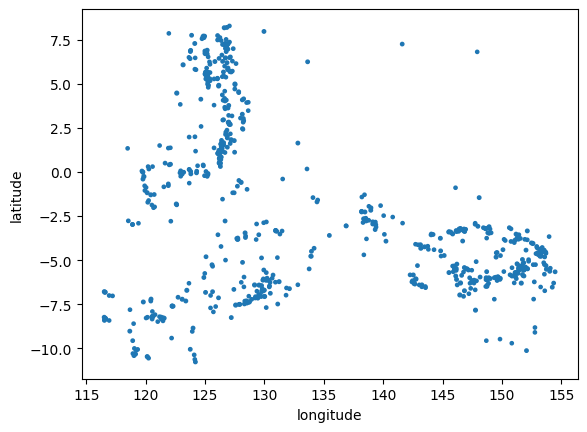

In [9]:
depth = df['depth']
long = df['longitude']

df.plot.scatter(x = 'longitude' , y = 'latitude', s = df['mag'])

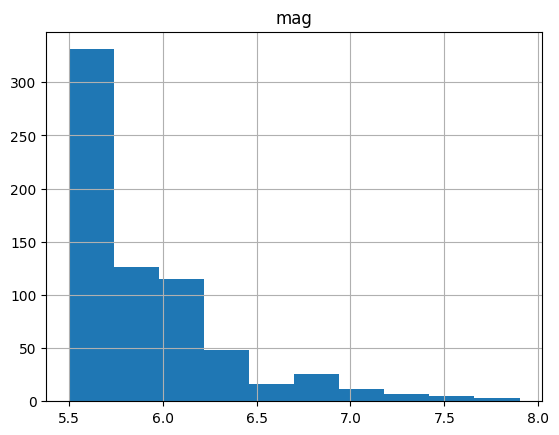

In [10]:
df.hist(column=["mag"])
plt.show()

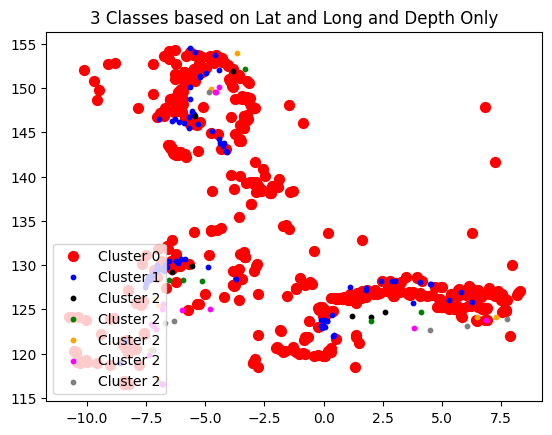

In [11]:
depth = df['depth']
long = df['longitude']

# df.plot.scatter(x = 'longitude' , y = 'latitude', s = df['mag'])
plt.scatter(lat[depth<100], long[depth<100], s=50, c='red', label ='Cluster 0')
plt.scatter(lat[(depth>=100) & (depth<200)], long[(depth>=100) & (depth<200)], s=10, c='blue', label ='Cluster 1')
plt.scatter(lat[(depth>=200) & (depth<300)], long[(depth>=200) & (depth<300)], s=10, c='black', label ='Cluster 2')
plt.scatter(lat[(depth>=300) & (depth<400)], long[(depth>=300) & (depth<400)], s=10, c='green', label ='Cluster 2')
plt.scatter(lat[(depth>=400) & (depth<500)], long[(depth>=400) & (depth<500)], s=10, c='orange', label ='Cluster 2')
plt.scatter(lat[(depth>=500) & (depth<600)], long[(depth>=500) & (depth<600)], s=10, c='magenta', label ='Cluster 2')
plt.scatter(lat[(depth>=600) & (depth<700)], long[(depth>=600) & (depth<700)], s=10, c='grey', label ='Cluster 2')


plt.legend(loc = 'lower left')
plt.title('3 Classes based on Lat and Long and Depth Only')
plt.show()

In [12]:
maxmag = df['mag'].max()
print('maxmag' , maxmag)
minmag = df['mag'].min()
print('minmag' , minmag)

maxdep = df['depth'].max()
print('maxdep' , maxdep)
mindep = df['depth'].min()
print('mindep' , mindep)

maxmag 7.9
minmag 5.5
maxdep 652.53
mindep 4.0


**Now make another scatter plot showing the latitudes and longitudes, but with the marker size representing the magnitude and the colour representing the depth**  Hint - scale the magnitudes to 20*(mag - min_mag)/(max_mag-min_mag)

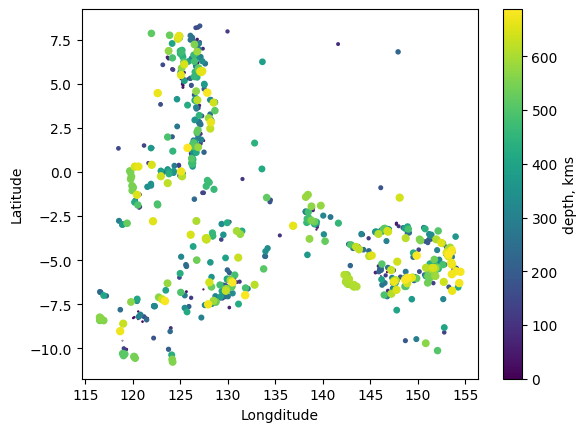

In [13]:
#df.plot.scatter(x = 'lat', y = 'long', s = 10*(df['mag']/(df['mag'].max())  ))
lat = df['latitude']
long = df['longitude']
depth = df['depth']
mag = df['mag']
# stations = df['stations']
s = [0.3*mag/maxmag  for mag in range(len(mag))]
#c = [depth/maxdep  for depth in range(len(depth))]
c = [depth for depth in range(len(depth))]
plt.scatter(long, lat, s=s, c=c )
plt.colorbar(label = 'depth, kms')
plt.xlabel('Longditude', fontsize=10)
plt.ylabel('Latitude', fontsize=10)
plt.show()

What can you say about the depths of the earthquakes?

**Now use the KMeans algorithm from scikit learn to cluster the eartquake locations according to their latitude and longitude.  How many clusters are appropriate?  Hint - look at the documentation for the dataset!**

In [14]:
from sklearn.cluster import KMeans

# The random_state needs to be the same number to get reproducible results
kmeans = KMeans(n_clusters=3) #, random_state=42)
y_km = kmeans.fit_predict(df[['latitude', 'longitude']])

kmeans.fit(df[['latitude', 'longitude']])
kmeans.labels_

print (y_km)


[0 2 1 0 0 2 1 0 0 1 1 1 1 1 0 1 2 1 1 1 1 1 1 1 1 2 2 2 2 2 0 2 2 1 2 0 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 1 0 2 1 0 2 2 2 2 2 2 2 2 2 2 1 0 0 2 2 1 2
 2 0 0 2 2 2 0 2 1 2 1 1 1 2 0 2 0 2 2 2 2 0 2 2 0 1 1 0 2 1 0 0 2 2 0 1 1
 2 0 1 1 2 2 0 0 1 2 0 2 2 2 2 0 0 2 1 1 1 1 2 0 1 2 2 0 0 1 2 0 0 0 2 2 1
 2 0 2 0 0 1 2 2 1 0 2 2 2 0 0 0 2 0 0 1 1 0 0 2 2 2 0 1 0 2 0 2 0 1 2 0 0
 2 1 0 2 0 0 2 2 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 2 0 0 0 0 0 0 2 0 0 0 2 1 0
 2 2 1 0 0 1 1 1 1 1 0 2 1 1 0 1 0 1 1 1 1 2 0 0 0 0 0 1 0 0 0 2 2 0 1 0 2
 1 1 2 0 2 2 2 2 2 2 2 1 0 2 2 2 0 0 2 0 0 0 0 0 2 1 2 0 2 1 0 2 0 0 1 0 1
 2 1 0 2 2 2 0 2 2 0 2 0 1 1 2 2 0 1 2 0 0 0 1 2 1 1 1 1 1 1 0 2 0 0 0 0 1
 2 1 1 1 2 2 0 0 2 2 2 2 1 2 2 0 0 0 0 2 2 2 1 1 2 2 0 2 2 2 0 0 0 0 2 0 1
 0 2 0 0 2 0 2 0 2 1 1 0 1 2 2 2 1 0 0 0 1 2 1 2 2 0 0 0 1 0 0 0 2 0 0 1 2
 1 0 2 1 2 1 1 0 2 2 1 1 2 0 2 2 1 1 0 0 1 2 0 2 2 0 1 0 1 2 2 2 0 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 0 0 2 0 2 1 1 1 2 2 2 2 0 0 2 2 2 2 2 2 2 0 0 0 0 1 0
 0 1 1 2 2 0 0 0 0 0 2 0 

**Make a scatter plot showing the cluster each earthquake belongs to**

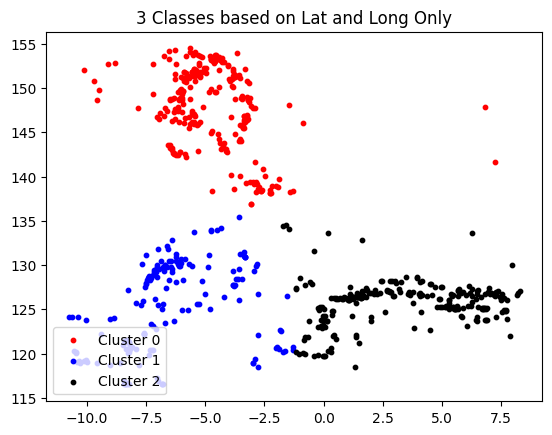

In [15]:
plt.scatter(lat[y_km==0], long[y_km==0], s=10, c='red', label ='Cluster 0')
plt.scatter(lat[y_km==1], long[y_km==1], s=10, c='blue', label ='Cluster 1')
plt.scatter(lat[y_km==2], long[y_km==2], s=10, c='black', label ='Cluster 2')
plt.legend(loc = 'lower left')
plt.title('3 Classes based on Lat and Long Only')
plt.show()

**Now perform KMeans clustering on the latitude, longitude and depth without scaling the inputs.  Plot the resulting clusters.  What do you notice?**

In [16]:
kmeans = KMeans(n_clusters=3) #, random_state=42)
y_km = kmeans.fit_predict(df[['latitude', 'longitude', 'depth']])
#kmeans.fit(df[['lat', 'long']])
#kmeans.labels_
#print (y_km)

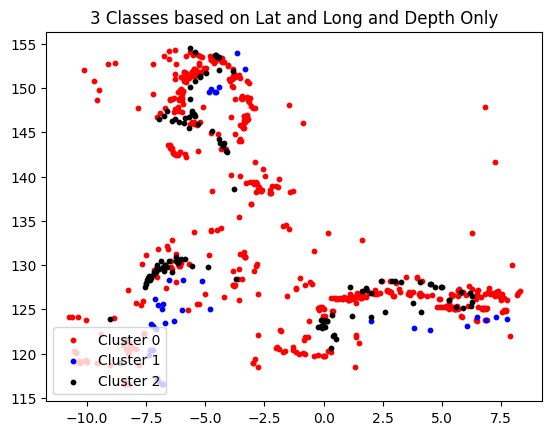

In [17]:
plt.scatter(lat[y_km==0], long[y_km==0], s=10, c='red', label ='Cluster 0')
plt.scatter(lat[y_km==1], long[y_km==1], s=10, c='blue', label ='Cluster 1')
plt.scatter(lat[y_km==2], long[y_km==2], s=10, c='black', label ='Cluster 2')
plt.legend(loc = 'lower left')
plt.title('3 Classes based on Lat and Long and Depth Only')
plt.show()

**Now perform clustering on the same three variables but this time normalize them (tip - use normalize from sklearn.preprocessing with axis=0).  Plot your results as lat vs long, long vs depth and lat vs depth.  What do you notice?**

In [18]:
from sklearn.preprocessing import Normalizer
normalizer_lat = Normalizer() #.fit(df)

#latNorm = normalizer.fit_transform(df[['lat']].values)
#longNorm = normalizer.transform(df[['long']])
#DpthNorm = normalizer.transform(df[['depth']])
#df[['lat']] = (df[['lat']] - df[['lat']].mean())/df[['lat']].std()
df[['latNorm']] = (df[['latitude']] - df[['latitude']].min())/(df[['latitude']].max() - df[['latitude']].min())
df[['longNorm']] = (df[['longitude']] - df[['longitude']].min())/(df[['longitude']].max() - df[['longitude']].min())
df[['dpthNorm']] = (df[['depth']] - df[['depth']].min())/(df[['depth']].max() - df[['depth']].min())
#print(df[['lat']])

<Axes: xlabel='latNorm', ylabel='longNorm'>

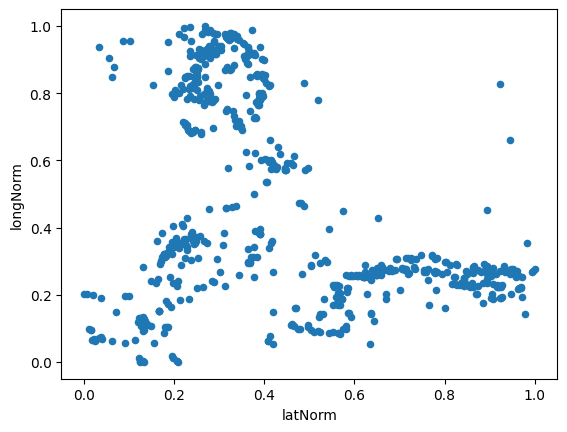

In [19]:
df.plot.scatter(x = 'latNorm', y = 'longNorm')

<Axes: xlabel='latNorm', ylabel='dpthNorm'>

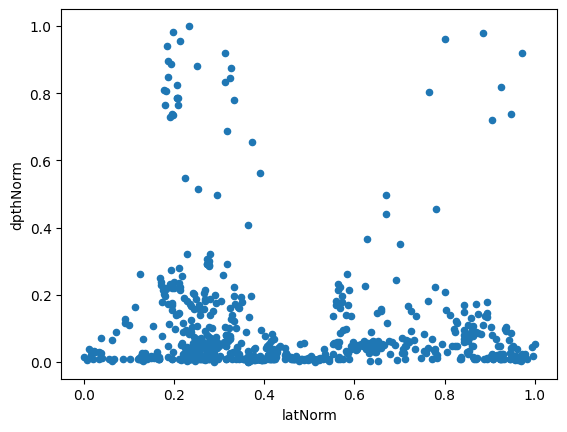

In [20]:
df.plot.scatter(x = 'latNorm', y = 'dpthNorm')

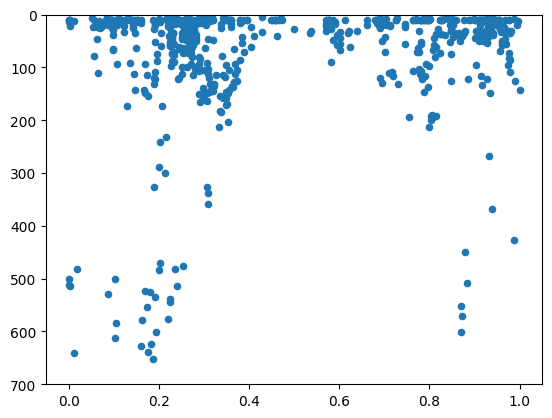

In [21]:
plt.scatter(x = df['longNorm'], y = df['depth'], marker = 'o', s=20)                   #'dpthNorm')
plt.ylim(700,0)
plt.show()


In [22]:
print(df)

                         time  latitude  longitude    depth  mag magType  \
0    2026-10-13T18:45:03.231Z   -5.4832   152.1364   20.842  6.0     mww   
1    2026-10-08T08:07:59.721Z    5.6177   125.1838   57.803  5.5     mww   
2    2026-10-03T22:55:55.358Z   -9.5672   118.9078   45.951  5.9     mww   
3    2026-09-26T14:08:18.875Z   -4.6288   152.8611   69.510  5.6     mww   
4    2026-09-20T09:17:36.531Z   -5.8986   146.1073  113.000  6.4     mww   
..                        ...       ...        ...      ...  ...     ...   
684  2016-11-09T14:50:59.680Z   -4.7403   149.8713  448.760  5.9     mww   
685  2016-11-01T19:03:30.100Z   -6.1039   148.6588   51.990  6.0     mww   
686  2016-10-28T05:26:55.910Z   -4.6721   153.2156   45.150  5.9     mww   
687  2016-10-27T08:17:50.160Z    1.3702   125.7580   61.000  5.8     mww   
688  2016-10-17T06:14:58.270Z   -6.0033   148.8871   42.000  6.8     mww   

       nst  gap   dmin   rms  ... horizontalError depthError magError magNst  \
0     8

**Now make a scatter plot of the magnitutes against the number of stations.  Is there a correlation?  Does this make sense?**

In [23]:
x,y,z = df['latitude'], df['longitude'], df['depth']

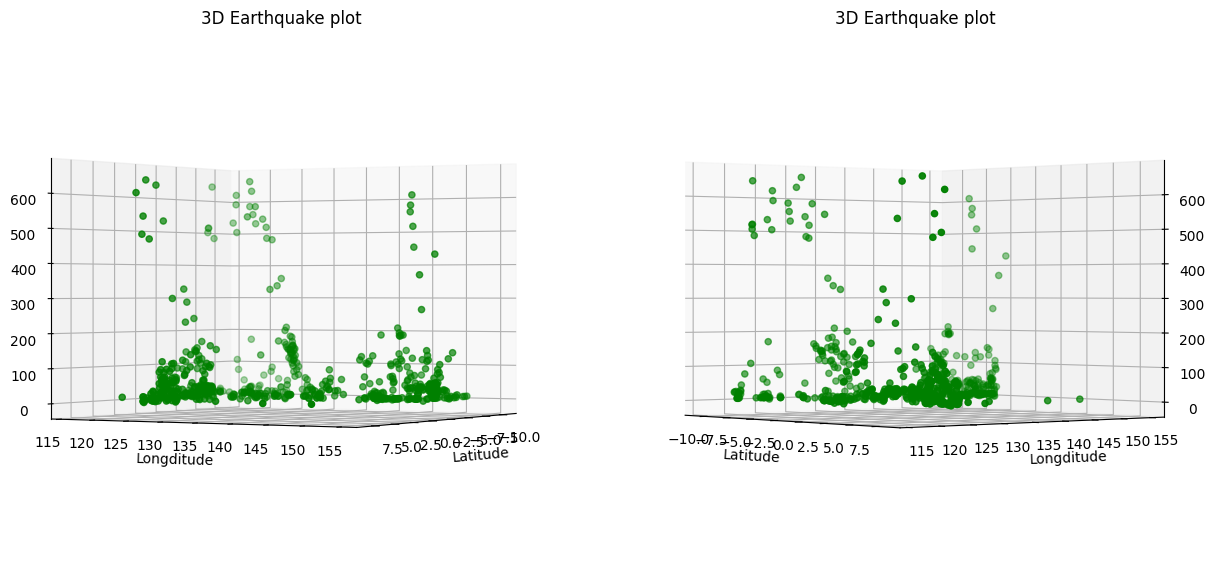

In [24]:
fig = plt.figure(figsize = (15,15))
#ax = fig.add_subplot(111, projection='3d')
ax = fig.add_subplot(1, 2, 1, projection='3d')

# load some test data for demonstration and plot a wireframe
ax.scatter3D(x, y, z, color = "green", marker  = 'o')
#ax.plot_wireframe(X, Y, Z, rstride=5, cstride=5)
ax.set_xlabel("Latitude")
ax.set_ylabel("Longditude")
ax.set_zlabel("Depth")
plt.title("3D Earthquake plot")
ax.view_init(0, 30)

#plt.show()

# # rotate the axes and update
# for angle in range(0, 360):
#     ax.view_init(30, angle)
#     plt.draw()
#     plt.pause(.001)

#fig = plt.figure(figsize = (8,8))
#ax = fig.add_subplot(111, projection='3d')
ax = fig.add_subplot(1, 2, 2, projection='3d')

# load some test data for demonstration and plot a wireframe
ax.scatter3D(x, y, z, color = "green", marker  = 'o')
#ax.plot_wireframe(X, Y, Z, rstride=5, cstride=5)
ax.set_xlabel("Latitude")
ax.set_ylabel("Longditude")
ax.set_zlabel("Depth")
plt.title("3D Earthquake plot")
ax.view_init(0, -40)

plt.show()

In [25]:
df.head()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,horizontalError,depthError,magError,magNst,status,locationSource,magSource,latNorm,longNorm,dpthNorm
0,2026-10-13T18:45:03.231Z,-5.4832,152.1364,20.842,6.0,mww,83.0,34,1.284,0.70,...,5.94,4.617,0.043,52.0,reviewed,us,us,0.277495,0.938444,0.025970
1,2026-10-08T08:07:59.721Z,5.6177,125.1838,57.803,5.5,mww,82.0,58,1.495,1.04,...,9.03,5.696,0.068,21.0,reviewed,us,us,0.859831,0.228519,0.082961
2,2026-10-03T22:55:55.358Z,-9.5672,118.9078,45.951,5.9,mww,82.0,63,4.600,1.29,...,9.53,6.808,0.062,25.0,reviewed,us,us,0.063254,0.063210,0.064686
3,2026-09-26T14:08:18.875Z,-4.6288,152.8611,69.510,5.6,mww,180.0,23,0.820,0.69,...,20.25,7.054,0.051,37.0,reviewed,us,us,0.322315,0.957532,0.101013
4,2026-09-20T09:17:36.531Z,-5.8986,146.1073,113.000,6.4,mww,100.0,22,3.636,0.67,...,7.35,1.936,0.039,62.0,reviewed,us,us,0.255704,0.779639,0.168072


In [26]:
import plotly.express as px
from plotly.express import scatter_3d
import plotly.graph_objs as go

import plotly.io as pio
plotly_template = pio.templates["plotly"]
plotly_template.layout


px.scatter_3d( data_frame= df, x=df['latitude'], y=df['longitude'], z=-df['depth'], color=df['mag'], symbol=None, size=df['mag'],
                          text=None, hover_name=None, hover_data=None, custom_data=None, error_x=None,
                          error_x_minus=None, error_y=None, error_y_minus=None, error_z=None, error_z_minus=None,
                          animation_frame=None, animation_group=None, category_orders=None, labels=None, size_max=None,
                          color_discrete_sequence=None, color_discrete_map=None, color_continuous_scale=px.colors.sequential.Rainbow, range_color=None,
                          color_continuous_midpoint=None, symbol_sequence=None, symbol_map=None, opacity=None, log_x=False, log_y=False, log_z=False,
                          range_x=None, range_y=None, range_z=None, title='3d View of Earthquakes', template=None, width=None, height=None)


#fig.show()
#fig.update_layout(legend_orientation="h",margin=dict(l=0, r=0, b=0, t=0))

